# w1 · M3v2 XGBoost (AP objective + isotonic calibration)

Trains **M3v2** only — M1 and M2 are not retouched.
Outputs go to `artifacts/sherlock_w1_xgb_v2/`; `artifacts/sherlock_w1/` is read-only.

Improvements over M3:
- Optuna maximises **average precision** (instead of minimising log-loss with a miscalibrated SPW).
- Wider search space: 13 hyperparameters including `scale_pos_weight`, `grow_policy`, `max_delta_step`, `colsample_bynode`, `max_bin`.
- **Isotonic calibration** fitted on the tune split after the final fit.
- Thresholds chosen by F1, **F2** (primary), and recall ≥ 0.70 on calibrated tune probabilities.

Limitation: tune is reused for the Optuna objective, calibration, and threshold selection
(same as the original pipeline — noted as a data-budget constraint).

## 1. Setup

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, precision_recall_curve

from src.models.constants import (
    EPS, SEED, DEV_COHORT, TEST_COHORT,
    XGB_V2_MODEL_ID, XGB_V2_TRIALS_FULL, XGB_V2_TRIALS_SMOKE,
)
from src.models.feature_preparation.data import load_metadata, load_cohorts
from src.models.feature_preparation.environment import model_environment
from src.models.feature_preparation.tabular_prep import make_phase_rows
from src.models.baselines.xgboost_v2 import (
    get_study_v2, run_xgboost_v2, apply_calibration,
)
from src.models.baselines.random_forest_data import encode_rf_frame
from src.models.evaluation.metrics import evaluate, select_threshold
from src.models.tunning.tunning import make_contract, contract_hash
from src.models.tunning.registry import SplitData

warnings.filterwarnings('ignore')

SMOKE_TEST = False
INPUT_DIR = Path('export-tabular-v5')
OUT_DIR = Path('artifacts/sherlock_w1_xgb_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

TOTAL_TRIALS = XGB_V2_TRIALS_SMOKE if SMOKE_TEST else XGB_V2_TRIALS_FULL
print('SMOKE_TEST:', SMOKE_TEST, '| trials:', TOTAL_TRIALS)

SMOKE_TEST: False | trials: 80


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data v5

Same two cohorts as the main notebook: February development, March test.
Checks that `dataset_version == 5` before proceeding.

In [2]:
META, FEATURES, CATEGORICAL, NUMERIC = load_metadata(INPUT_DIR)
assert META['dataset_version'] == 5, f"Expected dataset_version 5, got {META['dataset_version']}"
print('dataset_version:', META['dataset_version'], '| features:', len(FEATURES), '| categorical:', CATEGORICAL)

cohort_df, y_all, COHORT = load_cohorts(INPUT_DIR, META, FEATURES, DEV_COHORT, TEST_COHORT)

dataset_version: 5 | features: 59 | categorical: ['city', 'registered_via', 'last_payment_method_id']
train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 63) | users in both labelled months: 881701


## 3. Load saved split

Reuses `artifacts/sherlock_w1/split_indices.npz` — the exact same users as the v5 baseline run.
Verifies n per phase and churn rates match the saved summary.

In [3]:
_split_npz = np.load('artifacts/sherlock_w1/split_indices.npz')
SPLIT = {key: _split_npz[key] for key in ['fit', 'stop', 'tune', 'test']}
DEV_ROWS = _split_npz['development']

print('Split sizes (from saved split):')
for part, idx in SPLIT.items():
    print(f'  {part:5s}: {len(idx):>9,} | churn_rate: {y_all[idx].mean():.4f}')

Split sizes (from saved split):
  fit  :   744,699 | churn_rate: 0.0639
  stop :   124,117 | churn_rate: 0.0639
  tune :   124,115 | churn_rate: 0.0639
  test :   970,960 | churn_rate: 0.0899


## 4. PHASE_ROWS and tree_frame

Copied verbatim from `w1_tabular_models.ipynb`. Vocabulary is learned from the fit phase rows.

In [4]:
PHASE_ROWS = make_phase_rows(SPLIT, DEV_ROWS)

_tree_vocab = {}


def tree_vocab(phase):
    if phase not in _tree_vocab:
        rows = PHASE_ROWS[phase]
        _tree_vocab[phase] = {
            column: sorted(int(v) for v in pd.unique(cohort_df[column].iloc[rows].dropna()))
            for column in CATEGORICAL
        }
    return _tree_vocab[phase]


def tree_frame(rows, phase):
    frame = cohort_df.iloc[np.asarray(rows)][FEATURES].copy()
    cat_cols = frame.select_dtypes(include='category').columns
    for col in cat_cols:
        frame[col] = np.asarray(frame[col])
    vocab = tree_vocab(phase)
    for column in CATEGORICAL:
        codes = {level: idx for idx, level in enumerate(vocab[column])}
        frame[column] = frame[column].map(codes).fillna(-1).astype('int64')
    return frame


print('Phase rows:', {k: len(v) for k, v in PHASE_ROWS.items()})

Phase rows: {'fit': 744699, 'development': 992931}


## 5. Environment

In [5]:
XGB_DEVICE, ENV = model_environment(SEED)
print('XGB device:', XGB_DEVICE)
print(json.dumps(ENV, indent=2))

XGB device: cuda
{
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "sklearn": "1.9.1",
  "xgboost": "3.4.1",
  "optuna": "5.0.0",
  "xgb_device": "cuda"
}


## 6. Optuna study M3v2 (80 trials)

Direction: **maximize average precision** on tune.
First two trials enqueue M3v5 best params with original SPW and with SPW=1.
Study is stored in `artifacts/sherlock_w1_xgb_v2/optuna/studies.sqlite3` (separate from M1/M2/M3).

In [6]:
split_data = SplitData(SPLIT, y_all)

OPTUNA_DIR = OUT_DIR / 'optuna'
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
STORAGE = f"sqlite:///{(OPTUNA_DIR / 'studies.sqlite3').as_posix()}"

CONTRACT = make_contract(META, SPLIT, SMOKE_TEST, ENV)
CONTRACT_HASH = contract_hash(CONTRACT)

study = get_study_v2(XGB_V2_MODEL_ID, CONTRACT, STORAGE, SEED, TOTAL_TRIALS)

model, calibrator, xgb_data, study, counts = run_xgboost_v2(
    tree_frame=tree_frame,
    split_data=split_data,
    study=study,
    total_trials=TOTAL_TRIALS,
    out_dir=OPTUNA_DIR,
    device=XGB_DEVICE,
    max_rounds=3000,
    early_stop=100,
    log_period=100,
    seed=SEED,
)
print('Best params:', json.dumps(study.best_params, indent=2))

M3v2: budget=80, remaining=80


  0%|          | 0/80 [00:00<?, ?it/s]

M3v2: starting trial #0
[0]	validation_0-aucpr:0.49994
[100]	validation_0-aucpr:0.58111
[200]	validation_0-aucpr:0.58995
[300]	validation_0-aucpr:0.59036
[400]	validation_0-aucpr:0.58955
[405]	validation_0-aucpr:0.58944
M3v2: trial #0 COMPLETE | ap=0.59240 | 50.7s


Best trial: 0. Best value: 0.592398:   1%|▏         | 1/80 [00:50<1:06:56, 50.84s/it]

M3v2: starting trial #1
[0]	validation_0-aucpr:0.44838
[100]	validation_0-aucpr:0.59447
[200]	validation_0-aucpr:0.59662
[289]	validation_0-aucpr:0.59660
M3v2: trial #1 COMPLETE | ap=0.59858 | 34.8s


Best trial: 1. Best value: 0.598584:   2%|▎         | 2/80 [01:25<53:52, 41.44s/it]  

... (154 outputs left out)

M3v2: starting trial #79
[0]	validation_0-aucpr:0.36113
[100]	validation_0-aucpr:0.58423
[200]	validation_0-aucpr:0.59278
[300]	validation_0-aucpr:0.59581
[400]	validation_0-aucpr:0.59704
[500]	validation_0-aucpr:0.59757
[600]	validation_0-aucpr:0.59763
[655]	validation_0-aucpr:0.59762
M3v2: trial #79 COMPLETE | ap=0.59878 | 140.8s


Best trial: 47. Best value: 0.600606: 100%|██████████| 80/80 [2:43:38<00:00, 122.73s/it]

M3v2: best tune AP=0.60061 | trials {'complete': 80, 'pruned': 0, 'failed': 0}


[0]	validation_0-aucpr:0.37449
[100]	validation_0-aucpr:0.58131
[200]	validation_0-aucpr:0.58984
[300]	validation_0-aucpr:0.59347
[400]	validation_0-aucpr:0.59546
[500]	validation_0-aucpr:0.59628
[600]	validation_0-aucpr:0.59642
[700]	validation_0-aucpr:0.59652
[800]	validation_0-aucpr:0.59687
[900]	validation_0-aucpr:0.59687
[1000]	validation_0-aucpr:0.59702
[1100]	validation_0-aucpr:0.59699
[1153]	validation_0-aucpr:0.59700
M3v2 best_iteration: 1053 | elapsed: 9951s
Best params: {
  "grow_policy": "depthwise",
  "max_depth": 9,
  "learning_rate": 0.010246665906852534,
  "min_child_weight": 1.6532909915313736,
  "gamma": 0.09406308606663344,
  "subsample": 0.6934735798606839,
  "colsample_bytree": 0.7532257659158346,
  "colsample_bynode": 0.6444997385189897,
  "reg_alpha": 0.13113299350668028,
  "reg_lambda": 0.06789204949455295,
  "max_delta_step": 1.8429970240498958,
  "scale_pos_weight": 1.899771092929588,
  "max_bin": 256
}


In [7]:
trials_df = study.trials_dataframe()
complete = trials_df[trials_df['state'] == 'COMPLETE'].copy()

show_cols = ['number', 'value']
for col in ['user_attrs_tune_roc_auc', 'params_scale_pos_weight', 'params_max_depth', 'params_grow_policy']:
    if col in complete.columns:
        show_cols.append(col)

top10 = complete.sort_values('value', ascending=False).head(10)[show_cols]
top10.columns = [c.replace('user_attrs_', '').replace('params_', '') for c in top10.columns]
top10 = top10.rename(columns={'value': 'tune_ap'})
print('Top-10 trials by tune AP:')
top10.round(5)

Top-10 trials by tune AP:


,number,tune_ap,tune_roc_auc,scale_pos_weight,max_depth,grow_policy
47,47,0.60061,0.90074,1.89977,9.0,depthwise
33,33,0.60053,0.90072,1.05646,10.0,depthwise
38,38,0.60024,0.90062,2.02443,9.0,depthwise
60,60,0.60018,0.90056,1.29889,9.0,depthwise
72,72,0.60010,0.90052,1.44914,9.0,depthwise
68,68,0.60008,0.90051,1.34701,10.0,depthwise
51,51,0.60007,0.90037,1.31893,8.0,depthwise
49,49,0.60001,0.90052,1.29541,8.0,depthwise
42,42,0.60001,0.90063,1.57058,9.0,depthwise
36,36,0.60000,0.90058,1.40957,8.0,depthwise


## 7. Calibration

IsotonicRegression fitted on `(proba_tune_raw, y_tune)`. Applied to tune and test.
Log-loss and Brier are reported before and after calibration.

In [8]:
y_tune = y_all[SPLIT['tune']]
y_test = y_all[SPLIT['test']]

proba_tune_raw = model.predict_proba(xgb_data.tune_frame)[:, 1]
test_frame = tree_frame(SPLIT['test'], 'fit')
proba_test_raw = model.predict_proba(test_frame)[:, 1]

proba_tune_cal = apply_calibration(calibrator, proba_tune_raw)
proba_test_cal = apply_calibration(calibrator, proba_test_raw)

print('Calibration effect on tune split:')
print(f'  log_loss  before: {log_loss(y_tune, proba_tune_raw):.5f}  after: {log_loss(y_tune, proba_tune_cal):.5f}')
print(f'  brier     before: {brier_score_loss(y_tune, proba_tune_raw):.5f}  after: {brier_score_loss(y_tune, proba_tune_cal):.5f}')

Calibration effect on tune split:
  log_loss  before: 0.14917  after: 0.14064
  brier     before: 0.03972  after: 0.03753


## 8. Thresholds on calibrated tune probabilities

Three criteria using `precision_recall_curve` (exact thresholds, not a 99-point grid).
These thresholds are applied unchanged to test.

In [9]:
threshold_f1 = select_threshold(y_tune, proba_tune_cal, criterion='f1')
threshold_f2 = select_threshold(y_tune, proba_tune_cal, criterion='f2')
threshold_r70 = select_threshold(y_tune, proba_tune_cal, criterion='recall>=0.70')
threshold_uncal_f1 = select_threshold(y_tune, proba_tune_raw, criterion='f1')

print(f'Threshold @f1              : {threshold_f1:.4f}')
print(f'Threshold @f2 (primary)    : {threshold_f2:.4f}')
print(f'Threshold @recall>=0.70    : {threshold_r70:.4f}')
print(f'Threshold uncal @f1        : {threshold_uncal_f1:.4f}')

Threshold @f1              : 0.2752
Threshold @f2 (primary)    : 0.1176
Threshold @recall>=0.70    : 0.1379
Threshold uncal @f1        : 0.4267


## 9. Evaluation on test (March)

One row per threshold criterion on calibrated probabilities,
plus one row for uncalibrated @f1 to isolate the calibration contribution.

In [10]:
def _f2(row):
    p, r = row['precision_churn'], row['recall_churn']
    return 5 * p * r / (4 * p + r) if (4 * p + r) > 0 else 0.0


eval_rows = [
    {**evaluate(y_test, proba_test_cal,  'M3v2 @f1',           threshold_f1),   'criterion': 'f1'},
    {**evaluate(y_test, proba_test_cal,  'M3v2 @f2',           threshold_f2),   'criterion': 'f2'},
    {**evaluate(y_test, proba_test_cal,  'M3v2 @recall>=0.70', threshold_r70),  'criterion': 'recall>=0.70'},
    {**evaluate(y_test, proba_test_raw,  'M3v2 uncal @f1',     threshold_uncal_f1), 'criterion': 'f1 (sin calibrar)'},
]
test_df = pd.DataFrame(eval_rows)
test_df['f2_churn'] = test_df.apply(_f2, axis=1)

DISPLAY = ['model_id', 'criterion', 'roc_auc', 'average_precision', 'log_loss', 'brier',
           'precision_churn', 'recall_churn', 'f1_churn', 'f2_churn', 'FN', 'FP', 'threshold']
test_df[DISPLAY].round(5)

,model_id,criterion,roc_auc,average_precision,log_loss,brier,precision_churn,recall_churn,f1_churn,f2_churn,FN,FP,threshold
0,M3v2 @f1,f1,0.86423,0.58995,0.20369,0.05423,0.65861,0.51116,0.57560,0.53512,42690,23139,0.27523
1,M3v2 @f2,f2,0.86423,0.58995,0.20369,0.05423,0.48097,0.64594,0.55138,0.60447,30920,60874,0.11765
2,M3v2 @recall>=0.70,recall>=0.70,0.86423,0.58995,0.20369,0.05423,0.48187,0.64515,0.55168,0.60420,30989,60580,0.13788
3,M3v2 uncal @f1,f1 (sin calibrar),0.86462,0.59601,0.19665,0.05306,0.65887,0.51083,0.57548,0.53487,42719,23097,0.42670


## 10. Comparison vs M2 / M3 from v5 baseline

In [11]:
prev = pd.read_csv('artifacts/sherlock_w1/metrics/test_metrics.csv')
prev = prev[prev['model_id'].isin(['M2', 'M3'])].copy()
prev['criterion'] = 'f1'
prev['f2_churn'] = prev.apply(_f2, axis=1)

m3v2_rows = test_df[test_df['criterion'].isin(['f1', 'f2', 'recall>=0.70'])].copy()

COMPARE_COLS = ['model_id', 'criterion', 'roc_auc', 'average_precision', 'log_loss', 'brier',
                'precision_churn', 'recall_churn', 'f1_churn', 'f2_churn', 'FN', 'FP', 'threshold']

comparison = pd.concat(
    [prev[COMPARE_COLS], m3v2_rows[COMPARE_COLS]],
    ignore_index=True,
)

METRICS_DIR = OUT_DIR / 'metrics'
METRICS_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(METRICS_DIR / 'comparison_vs_v5.csv', index=False)
print('Saved comparison_vs_v5.csv')
comparison.round(5)

Saved comparison_vs_v5.csv


,model_id,criterion,roc_auc,average_precision,log_loss,brier,precision_churn,recall_churn,f1_churn,f2_churn,FN,FP,threshold
0,M2,f1,0.86320,0.59329,0.20318,0.05482,0.63791,0.53851,0.58401,0.55583,40302,26694,0.26000
1,M3,f1,0.85198,0.58818,0.48862,0.14981,0.60937,0.54244,0.57396,0.55462,39959,30367,0.88000
2,M3v2 @f1,f1,0.86423,0.58995,0.20369,0.05423,0.65861,0.51116,0.57560,0.53512,42690,23139,0.27523
3,M3v2 @f2,f2,0.86423,0.58995,0.20369,0.05423,0.48097,0.64594,0.55138,0.60447,30920,60874,0.11765
4,M3v2 @recall>=0.70,recall>=0.70,0.86423,0.58995,0.20369,0.05423,0.48187,0.64515,0.55168,0.60420,30989,60580,0.13788


## 11. Figures

PR curve (M2 v5, M3 v5, M3v2), calibration reliability, feature importance (gain top-20), Optuna history.

M2 and M3 development models are loaded from `artifacts/sherlock_w1/models/development/`
to generate test-set probabilities for the PR curve comparison.

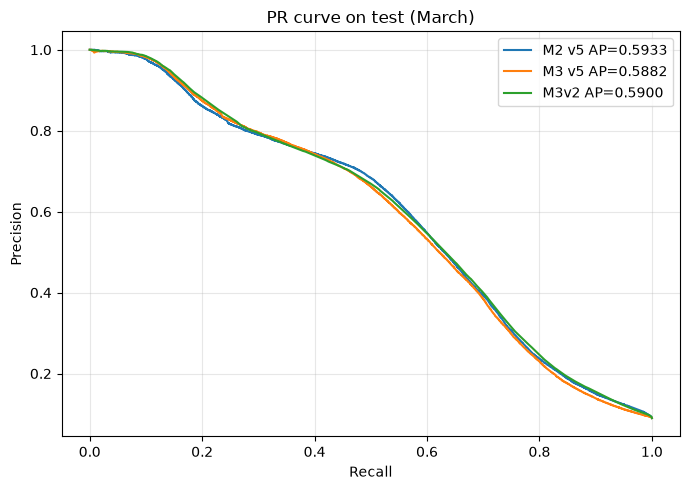

In [12]:
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load M2/M3 development models for comparison PR curves
m2_dev = joblib.load('artifacts/sherlock_w1/models/development/M2.joblib')
m3_dev = joblib.load('artifacts/sherlock_w1/models/development/M3.joblib')

preproc_info = json.loads(Path('artifacts/sherlock_w1/preprocessing/development.json').read_text())
rf_vocab = preproc_info['random_forest_vocabulary']
test_rf_frame = encode_rf_frame(
    cohort_df.iloc[SPLIT['test']], rf_vocab, FEATURES, CATEGORICAL
)
proba_test_m2 = m2_dev.predict_proba(test_rf_frame)[:, 1]
proba_test_m3 = m3_dev.predict_proba(tree_frame(SPLIT['test'], 'development'))[:, 1]

fig, ax = plt.subplots(figsize=(7, 5))
for label, proba in [('M2 v5', proba_test_m2), ('M3 v5', proba_test_m3), ('M3v2', proba_test_cal)]:
    p, r, _ = precision_recall_curve(y_test, proba)
    from sklearn.metrics import average_precision_score as aps
    ap = aps(y_test, proba)
    ax.plot(r, p, label=f'{label} AP={ap:.4f}')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('PR curve on test (March)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'pr_curve.png', dpi=120)
plt.show()

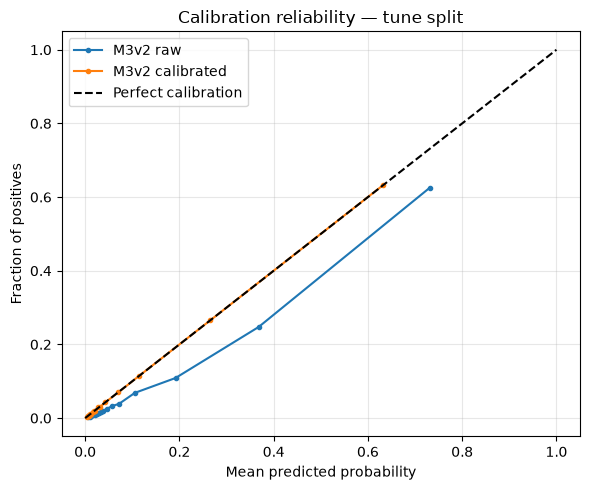

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, proba in [('M3v2 raw', proba_tune_raw), ('M3v2 calibrated', proba_tune_cal)]:
    frac_pos, mean_pred = calibration_curve(y_tune, proba, n_bins=20, strategy='quantile')
    ax.plot(mean_pred, frac_pos, marker='o', markersize=3, label=label)
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration reliability — tune split')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'calibration_reliability.png', dpi=120)
plt.show()

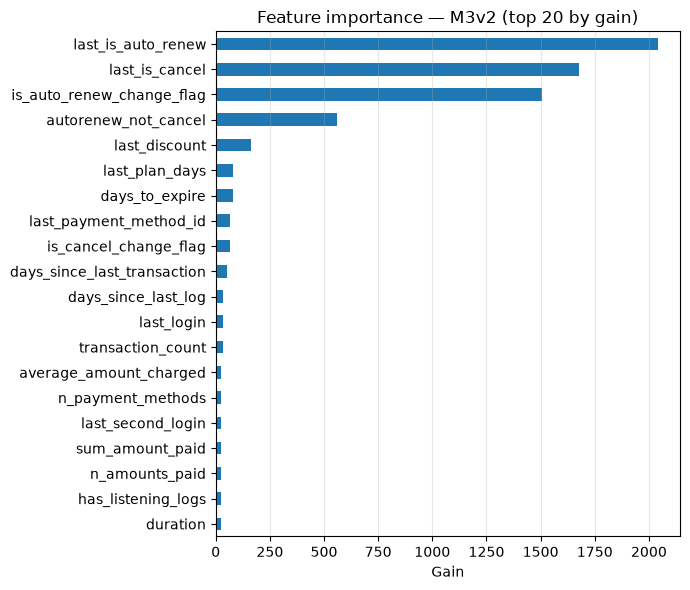

In [14]:
importance = model.get_booster().get_score(importance_type='gain')
imp_series = pd.Series(importance).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(7, 6))
imp_series[::-1].plot(kind='barh', ax=ax)
ax.set_xlabel('Gain')
ax.set_title('Feature importance — M3v2 (top 20 by gain)')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'feature_importance.png', dpi=120)
plt.show()

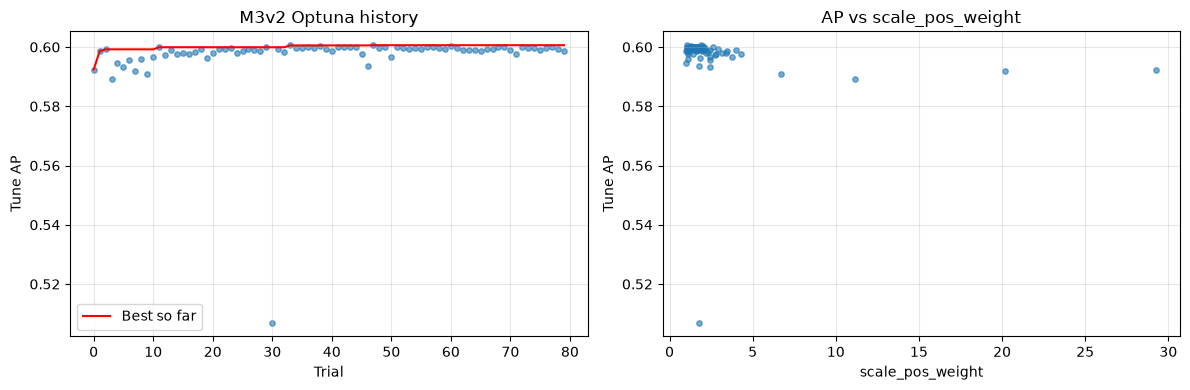

In [15]:
complete_sorted = complete.sort_values('number')
best_so_far = complete_sorted['value'].cummax()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(complete_sorted['number'], complete_sorted['value'], s=15, alpha=0.6)
axes[0].plot(complete_sorted['number'], best_so_far, color='red', linewidth=1.5, label='Best so far')
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('Tune AP')
axes[0].set_title('M3v2 Optuna history')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

if 'params_scale_pos_weight' in complete_sorted.columns:
    axes[1].scatter(complete_sorted['params_scale_pos_weight'], complete_sorted['value'], s=15, alpha=0.6)
    axes[1].set_xlabel('scale_pos_weight')
    axes[1].set_ylabel('Tune AP')
    axes[1].set_title('AP vs scale_pos_weight')
    axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'optuna_history.png', dpi=120)
plt.show()

## 12. Save artifacts

```
artifacts/sherlock_w1_xgb_v2/
  models/            M3v2.joblib, M3v2_isotonic.joblib
  optuna/            studies.sqlite3, M3v2_trials.csv, M3v2_best_params.json
  metrics/           comparison_vs_v5.csv
  figures/           pr_curve.png, calibration_reliability.png,
                     feature_importance.png, optuna_history.png
  best_params.json
  thresholds.json
  run_metadata.json
```

In [16]:
MODELS_DIR = OUT_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(model, MODELS_DIR / 'M3v2.joblib')
joblib.dump(calibrator, MODELS_DIR / 'M3v2_isotonic.joblib')

thresholds = {
    'f1': float(threshold_f1),
    'f2': float(threshold_f2),
    'recall>=0.70': float(threshold_r70),
}
(OUT_DIR / 'best_params.json').write_text(json.dumps(study.best_params, indent=2))
(OUT_DIR / 'thresholds.json').write_text(json.dumps(thresholds, indent=2))

run_metadata = {
    'model_id': XGB_V2_MODEL_ID,
    'smoke_test': SMOKE_TEST,
    'total_trials': TOTAL_TRIALS,
    'best_iteration': int(getattr(model, 'best_iteration', 3000)),
    'tune_ap': float(study.best_value),
    'thresholds': thresholds,
    'env': ENV,
    'contract_hash': CONTRACT_HASH,
    'counts': counts,
}
(OUT_DIR / 'run_metadata.json').write_text(json.dumps(run_metadata, indent=2))

print('Artifacts saved in:', OUT_DIR.resolve())
print('run_metadata:', json.dumps(run_metadata, indent=2))

Artifacts saved in: C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\artifacts\sherlock_w1_xgb_v2
run_metadata: {
  "model_id": "M3v2",
  "smoke_test": false,
  "total_trials": 80,
  "best_iteration": 1053,
  "tune_ap": 0.6006062161278203,
  "thresholds": {
    "f1": 0.27522939443588257,
    "f2": 0.11764705926179886,
    "recall>=0.70": 0.1378830075263977
  },
  "env": {
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "sklearn": "1.9.1",
    "xgboost": "3.4.1",
    "optuna": "5.0.0",
    "xgb_device": "cuda"
  },
  "contract_hash": "cbeb5c05d4c8",
  "counts": {
    "complete": 80,
    "pruned": 0,
    "failed": 0
  }
}
